# Regressão - Preço de anúncios do Airbnb em NYC

**Por:** Carolina Amorim e Lara Abduni

Neste projeto, o objetivo foi prever o preço por noite (`price`, em US$) de um anúncio do Airbnb em NYC a partir de características como localização, tipo de quarto, disponibilidade e histórico de reviews.

**Dataset:** [New York City Airbnb Open Data](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data) (Kaggle) — 48.895 anúncios de 2019, 16 colunas.

In [3]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV, learning_curve)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import loguniform, randint, uniform

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

## Carregamento e preparação dos dados

O pipeline seguido foi: carregar, inspecionar rapidamente, separar treino/teste antes de qualquer ajuste e
deixar todo o pré-processamento dentro de um `Pipeline` com `ColumnTransformer`.

In [4]:
if os.path.exists("AB_NYC_2019.csv"):
    caminho = "AB_NYC_2019.csv"
else:
    import kagglehub
    pasta = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")
    caminho = os.path.join(pasta, "AB_NYC_2019.csv")

df = pd.read_csv(caminho)
print(df.shape)
df.head()

(48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [5]:
print("Valores ausentes por coluna:")
print(df.isna().sum()[df.isna().sum() > 0])
print()
print(df["price"].describe(percentiles=[.5, .9, .99]).round(1))
print("Anúncios com preço = 0:", (df["price"] == 0).sum())

Valores ausentes por coluna:
name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

count    48895.0
mean       152.7
std        240.2
min          0.0
50%        106.0
90%        269.0
99%        799.0
max      10000.0
Name: price, dtype: float64
Anúncios com preço = 0: 11


**Decisões de limpeza**

- **Colunas descartadas:** `id`, `host_id` (identificadores), `name` e `host_name` (texto livre) e `last_review` (data, a
  informação útil — se o anúncio tem reviews e com que frequência — já está em `number_of_reviews` e `reviews_per_month`).
- **`reviews_per_month` ausente** acontece exatamente quando o anúncio não tem nenhuma review (`number_of_reviews == 0`),
  então o valor correto é **0**, não a média.
- **Preço:** removemos os 11 anúncios com preço 0 (erro de cadastro) e, no treino, cortamos os preços acima do
  **percentil 99** (aproximadamente 800 dólares), que são poucos anúncios com valores extremos (até 10.000 dólares) que dominariam o erro
  quadrático. O mesmo limite, calculado só no treino, é aplicado ao teste — ou seja, o modelo vale para anúncios de até
  esse valor.

In [6]:
assert ((df["number_of_reviews"] == 0) == df["reviews_per_month"].isna()).all()

df = df[df["price"] > 0].copy()
df = df.drop(columns=["id", "host_id", "name", "host_name", "last_review"])

X = df.drop(columns="price")
y = df["price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

limite = y_train.quantile(0.99)
mask_tr, mask_te = y_train <= limite, y_test <= limite
X_train, y_train = X_train[mask_tr], y_train[mask_tr]
X_test, y_test = X_test[mask_te], y_test[mask_te]

print(f"Limite de preço (p99 do treino): US$ {limite:.0f}")
print("Treino:", X_train.shape, " Teste:", X_test.shape)

Limite de preço (p99 do treino): US$ 799
Treino: (38715, 10)  Teste: (9677, 10)


### Pipeline de pré-processamento (mesmo padrão da APS1)

- **Numéricas:** `reviews_per_month` imputada com 0, o resto com mediana, depois `StandardScaler`.
- **Categóricas:** `neighbourhood_group` (5 distritos), `room_type` (3 tipos) e `neighbourhood` (221 bairros) com
  `OneHotEncoder`. Para `neighbourhood`, bairros com menos de 50 anúncios no treino são agrupados em uma categoria chamada
  "infrequente" (`min_frequency=50`), para não criar várias de colunas praticamente vazias.

In [7]:
num_zero = ["reviews_per_month"]
num_med = ["latitude", "longitude", "minimum_nights", "number_of_reviews",
        "calculated_host_listings_count", "availability_365"]
cat_cols = ["neighbourhood_group", "room_type", "neighbourhood"]

def make_preprocessor():
    return ColumnTransformer([
        ("num_zero", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value=0)),
                            ("sc", StandardScaler())]), num_zero),
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                        ("sc", StandardScaler())]), num_med),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50,
                            sparse_output=False), cat_cols),
    ], verbose_feature_names_out=False)

def make_pipe(model):
    return Pipeline([("prep", make_preprocessor()), ("model", model)])

n_feats = make_preprocessor().fit(X_train).get_feature_names_out().shape[0]
print("Número de features depois do pré-processamento:", n_feats)

Número de features depois do pré-processamento: 104


## 1. Seleção e implementação dos modelos

**Modelos escolhidos**
- **Dummy** (`DummyRegressor`, preve a média do treino): linha de base — qualquer modelo útil precisa superá-lo.
- **Linear com regularização** (`Ridge`, penalidade L2): modelo mais simples e interpretável, a regularização controla a
  magnitude dos coeficientes, o que importa porque tem muitas colunas one-hot correlacionadas (bairro × distrito).
- **Ensemble de árvores** (`HistGradientBoostingRegressor`): boosting de árvores, captura não-linearidades e interações
  (ex.: o efeito da localização depende do tipo de quarto) e é rápido em aproximadamente 39 mil linhas.

**Métrica:** **RMSE** (raiz do erro quadrático médio), em dólares — mesma unidade do preço, fácil de interpretar, e penaliza
mais os erros grandes. Reportamos também MAE e R² como apoio, mas todas as decisões são tomadas pelo RMSE.

**Validação:** `KFold` com 5 folds, embaralhado e com semente fixa, usado em todas as etapas.

In [8]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
SCORING = "neg_root_mean_squared_error"
resultados = {}

def avalia_cv(nome, modelo):
    s = cross_validate(modelo, X_train, y_train, cv=cv, n_jobs=-1,
                       scoring={"rmse": SCORING, "mae": "neg_mean_absolute_error", "r2": "r2"})
    resultados[nome] = {"RMSE (CV)": -s["test_rmse"].mean(), "± RMSE": s["test_rmse"].std(),
                        "MAE (CV)": -s["test_mae"].mean(), "R² (CV)": s["test_r2"].mean()}
    return pd.Series(resultados[nome]).round(3)

modelos_base = {
    "Dummy (média)": make_pipe(DummyRegressor(strategy="mean")),
    "Ridge (alpha=1, padrão)": make_pipe(Ridge()),
    "HistGB (padrão)": make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
}
for nome, m in modelos_base.items():
    avalia_cv(nome, m)
pd.DataFrame(resultados).T.round(2)

,RMSE (CV),± RMSE,MAE (CV),R² (CV)
Dummy (média),103.12,2.43,73.18,-0.0
"Ridge (alpha=1, padrão)",79.66,2.15,49.83,0.4
HistGB (padrão),72.88,1.85,44.44,0.5


### 1.1 Seleção de hiperparâmetros

- **Ridge → `GridSearchCV`**: só há um hiperparâmetro relevante (alpha), então uma grade em escala logarítmica cobre bem o espaço.
- **HistGradientBoosting → `RandomizedSearchCV`**: vários hiperparâmetros interagindo, a busca aleatória explora o
  espaço com bem menos ajustes que uma grade completa.

Mesma métrica (RMSE) e mesma validação (KFold 5).

Melhor alpha: {'model__alpha': np.float64(1.0)}
RMSE (CV): 79.66


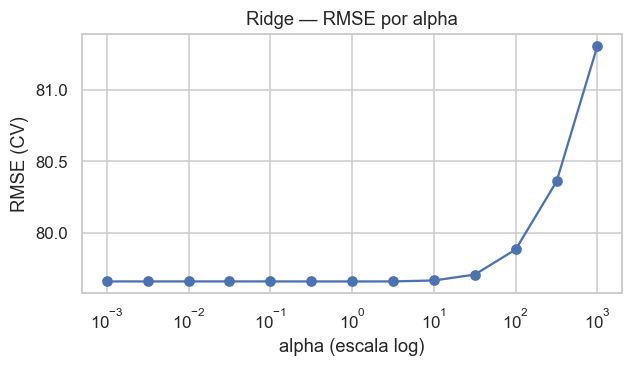

In [9]:
grid_ridge = GridSearchCV(make_pipe(Ridge()),
                          {"model__alpha": np.logspace(-3, 3, 13)},
                          cv=cv, scoring=SCORING, n_jobs=-1)
grid_ridge.fit(X_train, y_train)
print("Melhor alpha:", grid_ridge.best_params_)
print(f"RMSE (CV): {-grid_ridge.best_score_:.2f}")

res = pd.DataFrame(grid_ridge.cv_results_)
plt.figure(figsize=(6, 3.5))
plt.semilogx(res["param_model__alpha"].astype(float), -res["mean_test_score"], marker="o")
plt.xlabel("alpha (escala log)"); plt.ylabel("RMSE (CV)"); plt.title("Ridge — RMSE por alpha")
plt.tight_layout(); plt.show()

In [10]:
param_hgb = {
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_iter": randint(150, 600),
    "model__max_leaf_nodes": randint(15, 80),
    "model__min_samples_leaf": randint(10, 100),
    "model__l2_regularization": loguniform(1e-3, 10),
}
rs_hgb = RandomizedSearchCV(make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
                            param_hgb, n_iter=15, cv=cv, scoring=SCORING,
                            n_jobs=-1, random_state=RANDOM_STATE)
rs_hgb.fit(X_train, y_train)
print("Melhores hiperparâmetros:")
for k, v in rs_hgb.best_params_.items():
    print(f"  {k}: {v:.4g}")
print(f"RMSE (CV): {-rs_hgb.best_score_:.2f}")

Melhores hiperparâmetros:
  model__l2_regularization: 0.8111
  model__learning_rate: 0.04843
  model__max_iter: 364
  model__max_leaf_nodes: 76
  model__min_samples_leaf: 49
RMSE (CV): 72.73


In [11]:
avalia_cv("Ridge (tunado)", grid_ridge.best_estimator_)
avalia_cv("HistGB (tunado)", rs_hgb.best_estimator_)
tabela1 = pd.DataFrame(resultados).T.round(2)
tabela1

,RMSE (CV),± RMSE,MAE (CV),R² (CV)
Dummy (média),103.12,2.43,73.18,-0.0
"Ridge (alpha=1, padrão)",79.66,2.15,49.83,0.4
HistGB (padrão),72.88,1.85,44.44,0.5
Ridge (tunado),79.66,2.15,49.83,0.4
HistGB (tunado),72.73,1.80,44.26,0.5


**Resultado:** o HistGradientBoosting tunado é o melhor modelo até aqui (RMSE aprox. US$ 72,7, contra US$ 103 do
Dummy, uma redução de aprox. 29%). O tuning trouxe um ganho pequeno: no Ridge o melhor alpha foi o próprio padrão (1,0), e no
HistGB o RMSE caiu só de 72,9 para 72,7. Isso indica que o limite está nas features disponíveis e na forma do
modelo, não nos hiperparâmetros. Com  aprox. 38 mil linhas e 104 colunas, a regularização tem pouco efeito no Ridge, e a
diferença para o HistGB (aprox. US$7) vem das não-linearidades e interações que o modelo linear não captura.

### 1.2 Mudança no pipeline: transformação logarítmica do alvo

O preço é fortemente assimétrico à direita (muitos anúncios baratos, cauda longa de caros). Os efeitos
das variáveis também tendem a ser multiplicativos — ser um apartamento inteiro em Manhattan encarece em proporção,
não em um valor fixo de dólares. Modelar log(1 + price) deixa a distribuição mais simétrica e reduz a
influência dos anúncios caros no ajuste.

**Implementação:** `TransformedTargetRegressor(func=np.log1p, inverse_func=np.expm1)` envolvendo o pipeline. O modelo
treina em escala log, mas as previsões voltam para dólar — então o RMSE continua em dólares e é diretamente
comparável com a etapa anterior. Refazemos a seleção de hiperparâmetros com a mesma métrica e a mesma validação.

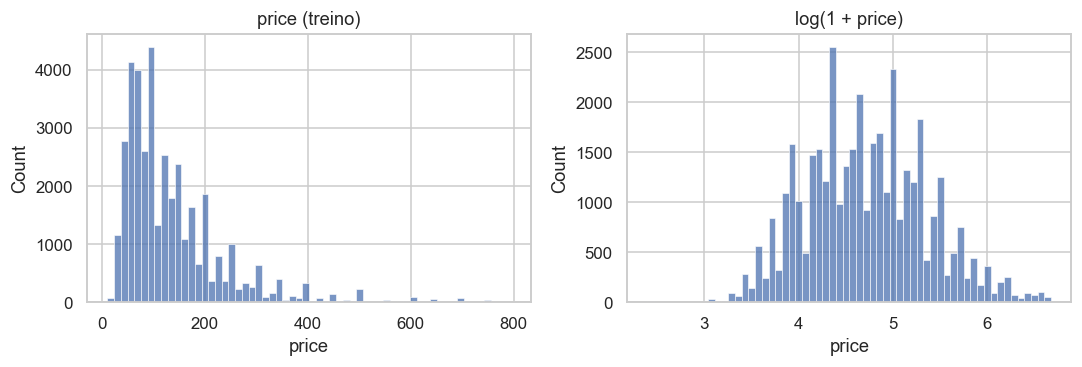

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
sns.histplot(y_train, bins=60, ax=ax[0]); ax[0].set_title("price (treino)")
sns.histplot(np.log1p(y_train), bins=60, ax=ax[1]); ax[1].set_title("log(1 + price)")
plt.tight_layout(); plt.show()

In [ ]:
def log_target(pipe):
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

param_hgb_log = {k.replace("model__", "regressor__model__"): v for k, v in param_hgb.items()}
rs_hgb_log = RandomizedSearchCV(log_target(make_pipe(HistGradientBoostingRegressor(random_state=RANDOM_STATE))),
                                param_hgb_log, n_iter=15, cv=cv, scoring=SCORING,
                                n_jobs=-1, random_state=RANDOM_STATE)
rs_hgb_log.fit(X_train, y_train)
print("Melhores hiperparâmetros (log):")
for k, v in rs_hgb_log.best_params_.items():
    print(f"  {k}: {v:.4g}")
print(f"RMSE (CV): {-rs_hgb_log.best_score_:.2f}")

# Tambem refazemos o Ridge, para ver o efeito da mudança no modelo linear
grid_ridge_log = GridSearchCV(log_target(make_pipe(Ridge())),
                            {"regressor__model__alpha": np.logspace(-3, 3, 13)},
                            cv=cv, scoring=SCORING, n_jobs=-1)
grid_ridge_log.fit(X_train, y_train)
print(f"\nRidge (log) — melhor alpha: {grid_ridge_log.best_params_['regressor__model__alpha']:.3g}, "
    f"RMSE (CV): {-grid_ridge_log.best_score_:.2f}")

,RMSE (CV),± RMSE,MAE (CV),R² (CV)
Dummy (média),103.12,2.43,73.18,-0.00
"Ridge (alpha=1, padrão)",79.66,2.15,49.83,0.40
HistGB (padrão),72.88,1.85,44.44,0.50
Ridge (tunado),79.66,2.15,49.83,0.40
HistGB (tunado),72.73,1.80,44.26,0.50
"Ridge (tunado, log)",80.54,2.39,46.20,0.39
"HistGB (tunado, log)",73.70,1.99,42.14,0.49


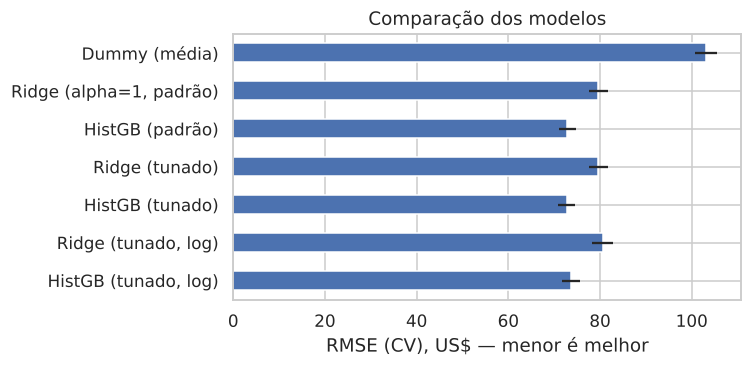

In [ ]:
avalia_cv("Ridge (tunado, log)", grid_ridge_log.best_estimator_)
avalia_cv("HistGB (tunado, log)", rs_hgb_log.best_estimator_)
tabela = pd.DataFrame(resultados).T.round(2)
display(tabela)

ax = tabela["RMSE (CV)"].plot.barh(xerr=tabela["± RMSE"], figsize=(7, 3.5), color="#4C72B0")
ax.invert_yaxis(); ax.set_xlabel("RMSE (CV), US$ — menor é melhor"); ax.set_title("Comparação dos modelos")
plt.tight_layout(); plt.show()

**Impacto da mudança:** O resultado foi misto e, para a nossa métrica, negativo:

| | RMSE (CV) | MAE (CV) |
|---|---|---|
| HistGB tunado (original) | **72,7** | 44,3 |
| HistGB tunado (log) | 73,7 | **42,1** |
| Ridge tunado (original) | **79,7** | 49,8 |
| Ridge tunado (log) | 80,5 | **46,2** |

Com o log, o MAE caiu aprox. 5%, mas o RMSE subiu aprox. US$ 1 nos dois modelos. A explicação está no que cada versão
otimiza: treinar em `log(price)` minimiza o erro quadrático relativo, e ao desfazer o log (`expm1`) a previsão fica
mais próxima da mediana condicional do preço do que da média. Como a distribuição é assimétrica, isso
subestima sistematicamente os anúncios caros — justamente onde os erros quadráticos pesam mais no RMSE. Já o MAE, menos
sensível a esses poucos erros grandes, melhora porque o modelo acerta melhor a massa de anúncios baratos.

**Conclusão:** como escolhemos o RMSE como métrica de decisão, o melhor modelo continua sendo o HistGB tunado sem log.
A lição é que a transformação do alvo precisa estar alinhada à métrica: se o objetivo fosse errar pouco em termos
percentuais (ou em MAE), o log seria a melhor escolha. Uma correção de viés na volta da escala log (ex.: *smearing* de
Duan) poderia reduzir parte dessa subestimação.

### 1.3 Curvas de aprendizado do melhor modelo

Melhor modelo: HistGB (tunado)


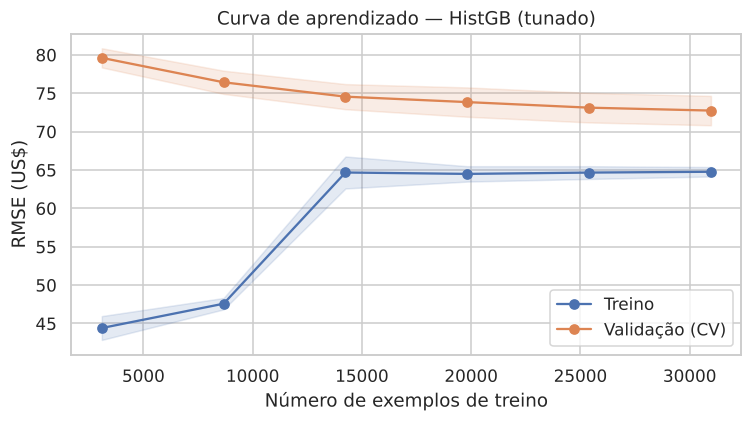

,n_treino,RMSE treino,RMSE validação
0,3097,44.41,79.61
1,8672,47.58,76.43
2,14247,64.67,74.56
3,19822,64.49,73.85
4,25397,64.66,73.12
5,30972,64.77,72.74


In [ ]:
melhor_nome = tabela["RMSE (CV)"].idxmin()
melhor = {"HistGB (tunado)": rs_hgb.best_estimator_,
          "HistGB (tunado, log)": rs_hgb_log.best_estimator_}.get(melhor_nome, rs_hgb_log.best_estimator_)
print("Melhor modelo:", melhor_nome)

tamanhos, tr_sc, va_sc = learning_curve(melhor, X_train, y_train, cv=cv, scoring=SCORING,
                                        train_sizes=np.linspace(0.1, 1.0, 6), n_jobs=-1, shuffle=True,
                                        random_state=RANDOM_STATE)
tr, va = -tr_sc, -va_sc
plt.figure(figsize=(7, 4))
for s, nome, c in [(tr, "Treino", "#4C72B0"), (va, "Validação (CV)", "#DD8452")]:
    plt.plot(tamanhos, s.mean(1), marker="o", label=nome, color=c)
    plt.fill_between(tamanhos, s.mean(1) - s.std(1), s.mean(1) + s.std(1), alpha=0.15, color=c)
plt.xlabel("Número de exemplos de treino"); plt.ylabel("RMSE (US$)")
plt.title(f"Curva de aprendizado — {melhor_nome}"); plt.legend(); plt.tight_layout(); plt.show()
pd.DataFrame({"n_treino": tamanhos, "RMSE treino": tr.mean(1), "RMSE validação": va.mean(1)}).round(2)

**Leitura da curva:** Com poucos dados (aprox. 3 mil exemplos) há um gap grande entre treino (RMSE ≈ 44) e validação
(≈ 80): o modelo memoriza a amostra pequena. Conforme o treino cresce, as curvas convergem e, a partir de ~20 mil
exemplos, ficam praticamente estáveis (treino ≈ 65, validação ≈ 73). O gap final pequeno (~US$ 8) indica pouca
variância/overfitting, e o fato de as duas curvas estabilizarem num erro alto indica que o modelo está limitado por
viés: mais dados do mesmo tipo trariam ganho marginal. Para melhorar de forma relevante, seria preciso informação
nova (tamanho do imóvel, número de quartos, comodidades, nota das reviews), não mais linhas.

## 2. Avaliação do melhor modelo no conjunto de teste

O melhor modelo é reajustado em todo o treino (já feito pelo `RandomizedSearchCV`) e avaliado **uma única vez** no
conjunto de teste, que não foi usado em nenhuma decisão anterior.

In [ ]:
y_pred = melhor.predict(X_test)
res_test = y_test - y_pred
metricas_teste = pd.Series({
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    "MAE": mean_absolute_error(y_test, y_pred),
    "R²": r2_score(y_test, y_pred),
    "RMSE do Dummy (teste)": np.sqrt(mean_squared_error(y_test, np.full_like(y_test, y_train.mean(), dtype=float))),
}).round(2)
metricas_teste

RMSE                      72.77
MAE                       44.35
R²                         0.50
RMSE do Dummy (teste)    102.50
dtype: float64

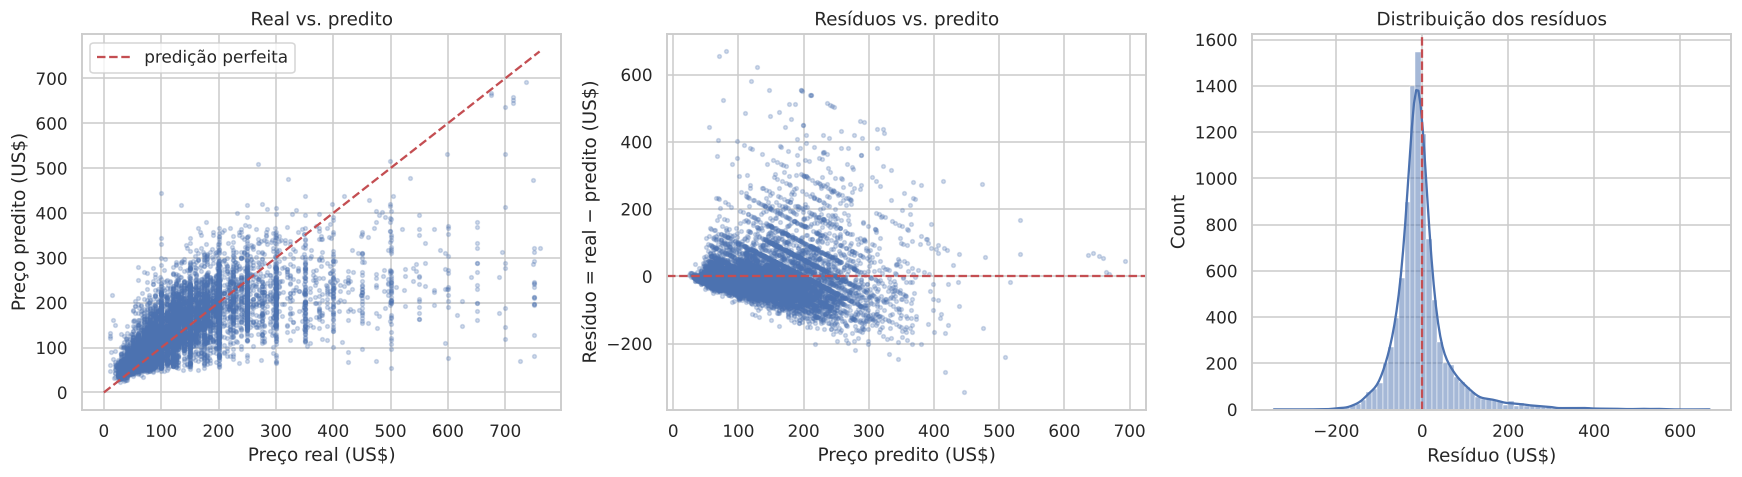

Média dos resíduos: 0.46 | Mediana: -10.06 | Assimetria: 2.53
Resíduos com |erro| > US$100: 9.9% dos anúncios


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ax[0].scatter(y_test, y_pred, s=6, alpha=0.25)
lim = [0, y_test.max()]
ax[0].plot(lim, lim, "r--", lw=1.5, label="predição perfeita")
ax[0].set_xlabel("Preço real (US$)"); ax[0].set_ylabel("Preço predito (US$)")
ax[0].set_title("Real vs. predito"); ax[0].legend()

ax[1].scatter(y_pred, res_test, s=6, alpha=0.25)
ax[1].axhline(0, color="r", ls="--", lw=1.5)
ax[1].set_xlabel("Preço predito (US$)"); ax[1].set_ylabel("Resíduo = real − predito (US$)")
ax[1].set_title("Resíduos vs. predito")

sns.histplot(res_test, bins=80, kde=True, ax=ax[2])
ax[2].axvline(0, color="r", ls="--", lw=1.5)
ax[2].set_xlabel("Resíduo (US$)"); ax[2].set_title("Distribuição dos resíduos")
plt.tight_layout(); plt.show()

print(f"Média dos resíduos: {res_test.mean():.2f} | Mediana: {res_test.median():.2f} | "
      f"Assimetria: {res_test.skew():.2f}")
print(f"Resíduos com |erro| > US$100: {(res_test.abs() > 100).mean():.1%} dos anúncios")

In [ ]:
# Erro por faixa de preço real — ajuda a entender onde o modelo erra mais
faixas = pd.cut(y_test, [0, 75, 150, 250, 400, limite])
pd.DataFrame({"faixa": faixas, "erro_abs": res_test.abs(), "residuo": res_test}) \
  .groupby("faixa", observed=True).agg(n=("erro_abs", "size"), MAE=("erro_abs", "mean"),
                                       residuo_medio=("residuo", "mean")).round(1)

,n,MAE,residuo_medio
faixa,,,
"(0.0, 75.0]",3082,21.9,-19.7
"(75.0, 150.0]",3692,35.7,-21.5
"(150.0, 250.0]",1940,45.8,5.9
"(250.0, 400.0]",712,101.7,90.2
"(400.0, 798.76]",251,273.4,273.1


**Análise do teste:** O RMSE no teste (US$ 72,8) é praticamente igual ao da validação cruzada (US$ 72,7), então a
estimativa da CV era confiável e não houve sobreajuste à validação. O modelo explica cerca de 50% da variância do
preço (R² = 0,50) e reduz o RMSE em ~29% em relação ao Dummy.

- **Real vs. predito:** os pontos acompanham a diagonal até ~US$ 250, mas acima disso ficam abaixo dela — o modelo
  "comprime" as previsões em direção à média e quase nunca prevê valores muito altos.
- **Resíduos vs. predito:** a dispersão cresce com o preço predito (formato de funil, heterocedasticidade): errar
  US$ 50 num anúncio de US$ 300 é muito mais comum do que num de US$ 60. As "listras" diagonais vêm dos preços
  redondos (US$ 100, 150, 200, …): para um preço real fixo, o resíduo cai linearmente conforme o predito aumenta.
- **Distribuição dos resíduos:** média ≈ 0, mas mediana ≈ −US$ 10 e assimetria positiva forte (2,5). Ou seja, na
  maioria dos anúncios o modelo superestima um pouco o preço e, numa minoria, subestima muito (cauda direita).
- **Por faixa de preço:** até US$ 150 o MAE fica entre US$ 22 e US$ 36, com leve superestimação, acima de US$ 400 o
  resíduo médio é de +US$ 273 (subestimação severa). Cerca de 10% dos anúncios têm erro acima de US$ 100.

## 3. Interpretação e explicabilidade

### 3.1 Modelo linear - 3 maiores coeficientes em magnitude

Usamos o **Ridge tunado na escala original** (US$). Como as numéricas estão padronizadas, cada coeficiente numérico
significa "variação de preço, em US$, para +1 desvio-padrão na variável"; para as one-hot, "diferença de preço em
relação às outras categorias do mesmo grupo", mantendo o resto constante.

,coeficiente (US$)
neighbourhood_Tribeca,103.0
neighbourhood_NoHo,82.4
room_type_Entire home/apt,67.8
neighbourhood_Midtown,65.4
neighbourhood_Flatiron District,65.2
neighbourhood_Inwood,-63.8
neighbourhood_Washington Heights,-59.6
neighbourhood_Cobble Hill,54.4
neighbourhood_group_Staten Island,-48.4
room_type_Shared room,-47.1


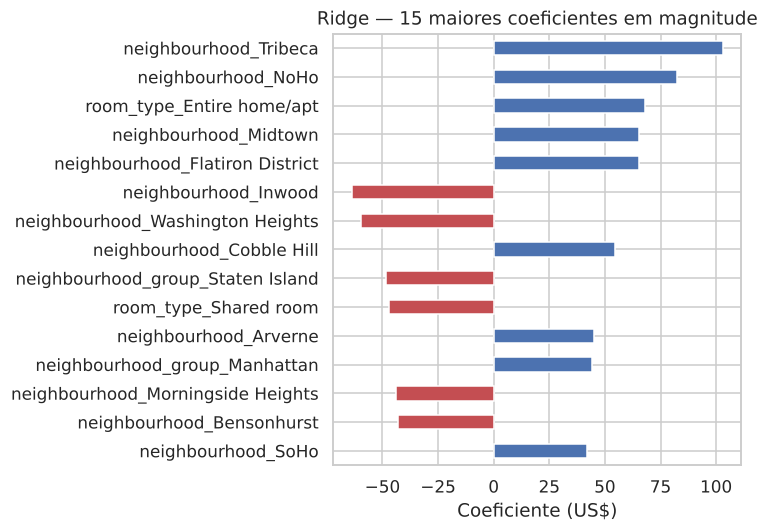

In [ ]:
ridge_pipe = grid_ridge.best_estimator_
nomes = ridge_pipe.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(ridge_pipe.named_steps["model"].coef_, index=nomes)
top_coef = coefs.reindex(coefs.abs().sort_values(ascending=False).index)
display(top_coef.head(10).round(1).to_frame("coeficiente (US$)"))

top_coef.head(15).iloc[::-1].plot.barh(figsize=(7, 5),
    color=["#C44E52" if v < 0 else "#4C72B0" for v in top_coef.head(15).iloc[::-1]])
plt.xlabel("Coeficiente (US$)"); plt.title("Ridge — 15 maiores coeficientes em magnitude")
plt.tight_layout(); plt.show()

Os três maiores coeficientes em magnitude são:

1. **`neighbourhood_Tribeca` (+US$ 103):** mantendo o resto constante, estar em Tribeca acrescenta cerca de US$ 100 à
   diária. É um dos bairros mais caros de Manhattan, então o sinal e a ordem de grandeza fazem sentido.
2. **`neighbourhood_NoHo` (+US$ 82):** mesmo raciocínio — bairro nobre de Manhattan, pequeno e muito valorizado.
3. **`room_type_Entire home/apt` (+US$ 68):** alugar o imóvel inteiro, em vez de um quarto, é o fator individual mais
   forte fora da localização. Do outro lado, `Shared room` tem −US$ 47.

Entre os negativos aparecem Inwood (−US$ 64) e Washington Heights (−US$ 60), no norte de Manhattan, e
Staten Island (−US$ 48): mostram que "estar em Manhattan" não basta, o bairro específico importa.

**Cuidados na interpretação:** (i) como não removemos uma categoria de referência no one-hot, cada coeficiente é
relativo à média das categorias do mesmo grupo, não a um bairro específico; (ii) bairro, distrito e
latitude/longitude carregam informação redundante, e o Ridge "divide" o efeito entre elas — o efeito total da
localização é maior do que qualquer coeficiente isolado; (iii) Tribeca e NoHo têm poucos anúncios, então esses
coeficientes são menos estáveis.

### 3.2 Modelo ensemble - 3 features mais importantes

O `HistGradientBoostingRegressor` não expõe `feature_importances_`, então usamos **importância por permutação** no
conjunto de teste: embaralhamos uma coluna original por vez e medimos o quanto o RMSE piora. Ela tem a vantagem de ser
calculada por coluna original (ex.: `room_type` inteiro, não cada categoria one-hot) e de não favorecer variáveis com
muitos valores distintos, como acontece com a importância por impureza.

,aumento no RMSE (US$),±
room_type,30.36,0.83
longitude,11.33,0.47
minimum_nights,11.26,0.53
availability_365,9.59,0.61
latitude,7.69,0.42
calculated_host_listings_count,2.61,0.42
number_of_reviews,2.00,0.15
reviews_per_month,1.97,0.23
neighbourhood,1.91,0.20
neighbourhood_group,0.23,0.06


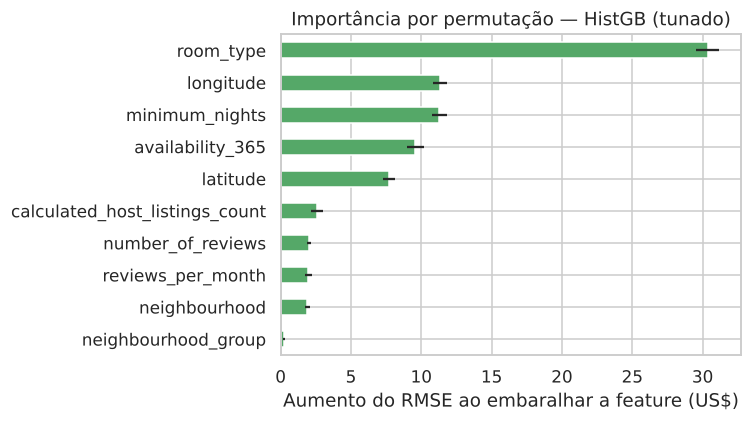

In [ ]:
amostra = X_test.sample(3000, random_state=RANDOM_STATE)
perm = permutation_importance(melhor, amostra, y_test.loc[amostra.index], scoring=SCORING,
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"aumento no RMSE (US$)": perm.importances_mean, "±": perm.importances_std},
                   index=amostra.columns).sort_values("aumento no RMSE (US$)", ascending=False)
display(imp.round(2))
imp["aumento no RMSE (US$)"].iloc[::-1].plot.barh(xerr=imp["±"].iloc[::-1], figsize=(7, 4), color="#55A868")
plt.xlabel("Aumento do RMSE ao embaralhar a feature (US$)")
plt.title(f"Importância por permutação — {melhor_nome}"); plt.tight_layout(); plt.show()

As três features mais importantes são:

1. **`room_type` (+US$ 30 no RMSE ao embaralhar):** de longe a mais importante — o tipo de acomodação define a faixa de
   preço antes de qualquer outra coisa. Coincide com o modelo linear.
2. **`longitude` (+US$ 11):** junto com `latitude` (5ª, +US$ 8), representa a localização. A longitude separa bem
   Manhattan (mais a oeste) do Queens e do Brooklyn mais periférico. Diferente do Ridge, o ensemble prefere as
   **coordenadas contínuas** aos bairros: as árvores conseguem recortar regiões no mapa diretamente.
3. **`minimum_nights` (+US$ 11):** anúncios com estadia mínima longa (≥ 30 noites, típica de aluguel mensal) têm
   diária bem menor. Esse efeito não aparecia entre os maiores coeficientes do Ridge, porque é não-linear (degrau em
   torno de 30 noites) - algo que as árvores captam e o modelo linear não.

**Cuidado:** `neighbourhood` e `neighbourhood_group` aparecem com importância baixa não porque a localização não
importe, mas porque sua informação já está em latitude/longitude. A importância por permutação subestima features
correlacionadas: ao embaralhar uma, o modelo ainda tem a outra.

### 3.3 SHAP no melhor modelo

Aplicamos o `TreeExplainer` ao HistGradientBoosting dentro do pipeline, sobre os dados já pré-processados (amostra de
1.500 anúncios do teste). Como o melhor modelo foi treinado na escala original, os **valores SHAP estão em US$**: o
valor base é a previsão média, e cada valor SHAP é quanto aquela feature empurrou a previsão para cima ou para baixo
naquele anúncio. A soma do valor base com todas as contribuições dá exatamente o preço predito.

Observação: o pré-processamento faz one-hot, então cada categoria aparece como uma coluna (ex.:
`room_type_Entire home/apt`). As numéricas aparecem padronizadas no eixo de cor do beeswarm.

,média |SHAP| (US$)
room_type_Entire home/apt,51.15
longitude,20.52
availability_365,15.88
latitude,12.62
minimum_nights,9.66
reviews_per_month,5.60
number_of_reviews,4.39
calculated_host_listings_count,2.77
neighbourhood_Midtown,2.39
room_type_Private room,1.99


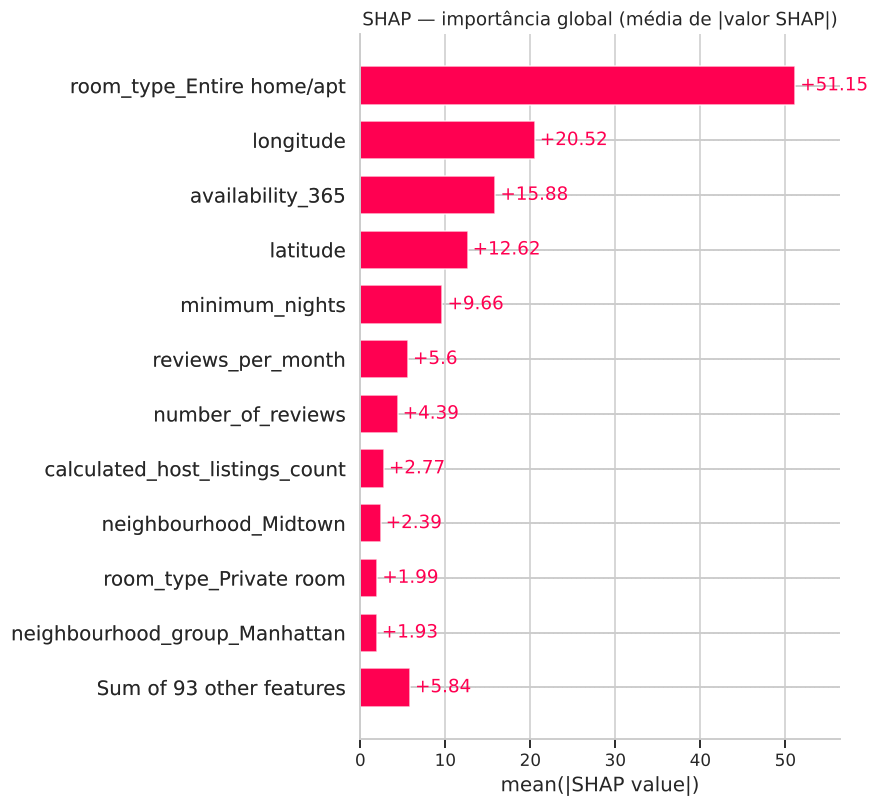

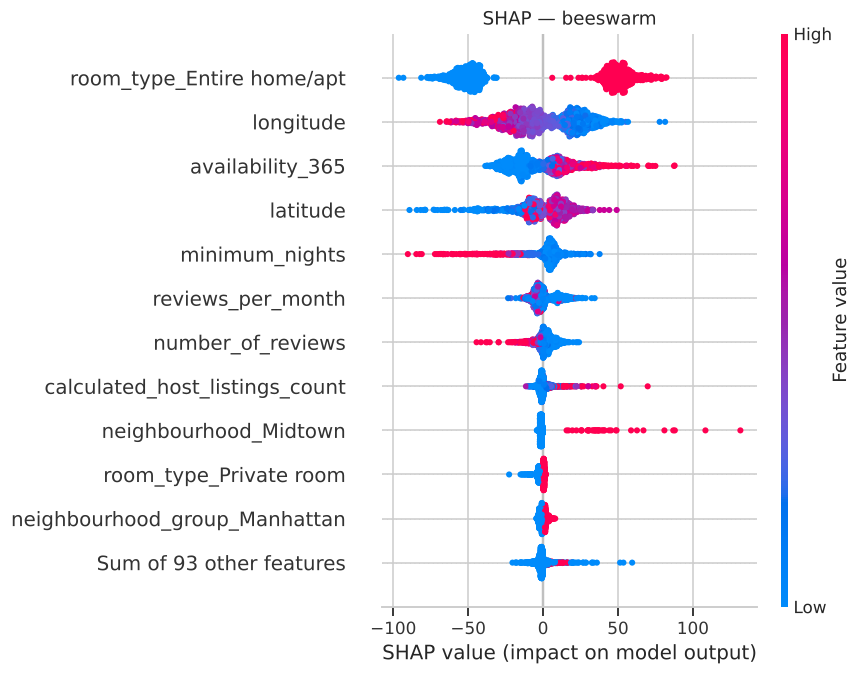

In [ ]:
if isinstance(melhor, TransformedTargetRegressor):
    pipe_final, escala_log = melhor.regressor_, True
else:
    pipe_final, escala_log = melhor, False
prep, hgb = pipe_final.named_steps["prep"], pipe_final.named_steps["model"]

X_shap = amostra.iloc[:1500]
Xt = pd.DataFrame(prep.transform(X_shap), columns=prep.get_feature_names_out(), index=X_shap.index)
explainer = shap.TreeExplainer(hgb)
sv = explainer(Xt)

media_abs = pd.Series(np.abs(sv.values).mean(0), index=Xt.columns).sort_values(ascending=False)
display(media_abs.head(10).round(2).to_frame("média |SHAP|" + (" (log)" if escala_log else " (US$)")))

shap.plots.bar(sv, max_display=12, show=False)
plt.title("SHAP — importância global (média de |valor SHAP|)"); plt.tight_layout(); plt.show()
shap.plots.beeswarm(sv, max_display=12, show=False)
plt.title("SHAP — beeswarm"); plt.tight_layout(); plt.show()

**Importância global.** O ranking do SHAP (média de |SHAP|, em US$) confirma o padrão da importância por permutação:

1. **`room_type_Entire home/apt` (~US$ 51):** é a feature dominante. No beeswarm os pontos se separam em dois blocos -
   imóvel inteiro empurra a previsão ~US$ 50 para cima, quarto privado/compartilhado ~US$ 50 para baixo.
2. **`longitude` (~US$ 21) e `latitude` (~US$ 13):** localização. Longitudes altas (mais a leste, Queens e Brooklyn
   periférico) puxam o preço para baixo, longitudes menores (Manhattan) puxam para cima. Latitudes baixas (sul do
   Brooklyn e Staten Island) reduzem o preço.
3. **`availability_365` (~US$ 16):** anúncios disponíveis o ano todo tendem a ser mais caros. Provavelmente são
   operações mais "comerciais" (anfitriões profissionais, apartamentos dedicados ao Airbnb), enquanto disponibilidade
   baixa é típica de quem aluga o próprio quarto de vez em quando.
4. **`minimum_nights` (~US$ 10):** estadia mínima alta (aluguel mensal) reduz a diária.

Outros sinais coerentes: muitas reviews puxam levemente o preço para baixo (anúncios baratos giram mais) e
`neighbourhood_Midtown` é a única categoria de bairro que aparece no topo - quando vale 1, aumenta bastante o preço.

A diferença em relação à permutação (onde `availability_365` ficou em 4º e `minimum_nights` em 3º) é esperada: o SHAP
mede quanto a feature move cada previsão, a permutação mede quanto o erro piora sem ela.

#### Três predições individuais

Escolhemos três anúncios contrastantes do conjunto de teste: o de menor preço predito, um mediano e o de
maior preço predito na amostra.

=== MENOR PREÇO PREDITO | real: US$ 35 | predito: US$ 26 ===


,neighbourhood_group,neighbourhood,room_type,minimum_nights,number_of_reviews,availability_365,calculated_host_listings_count
47212,Brooklyn,Williamsburg,Shared room,30,0,341,5


Valor base: 137.5 US$
Top-5 contribuições SHAP:
  room_type_Entire home/apt              -69.2 US$
  minimum_nights                         -24.3 US$
  longitude                              -12.0 US$
  room_type_Private room                  -9.9 US$
  availability_365                        +9.3 US$


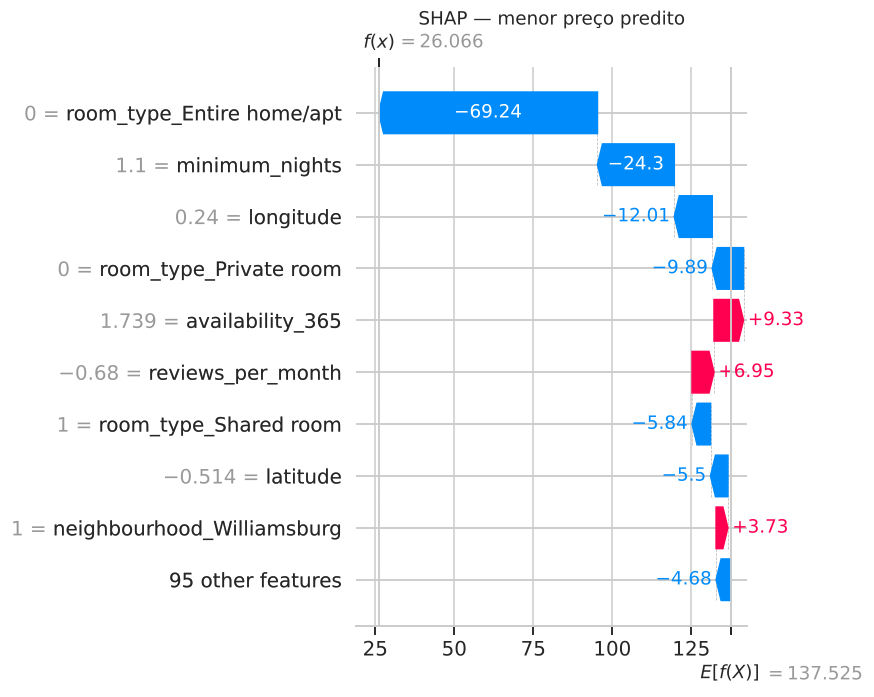

=== PREÇO PREDITO MEDIANO | real: US$ 100 | predito: US$ 123 ===


,neighbourhood_group,neighbourhood,room_type,minimum_nights,number_of_reviews,availability_365,calculated_host_listings_count
31558,Manhattan,Harlem,Entire home/apt,3,3,0,1


Valor base: 137.5 US$
Top-5 contribuições SHAP:
  room_type_Entire home/apt              +40.5 US$
  availability_365                       -23.7 US$
  longitude                              -22.1 US$
  latitude                               -10.9 US$
  minimum_nights                          +6.7 US$


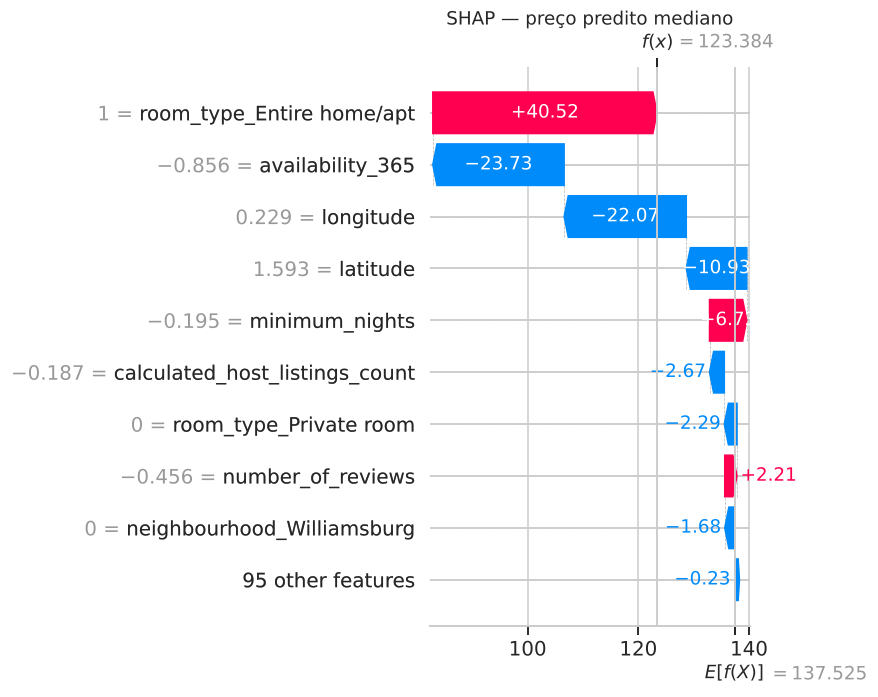

=== MAIOR PREÇO PREDITO | real: US$ 499 | predito: US$ 516 ===


,neighbourhood_group,neighbourhood,room_type,minimum_nights,number_of_reviews,availability_365,calculated_host_listings_count
19136,Manhattan,Midtown,Private room,3,7,365,12


Valor base: 137.5 US$
Top-5 contribuições SHAP:
  neighbourhood_Midtown                 +131.7 US$
  availability_365                       +87.4 US$
  calculated_host_listings_count         +69.8 US$
  longitude                              +55.2 US$
  room_type_Entire home/apt              -31.4 US$


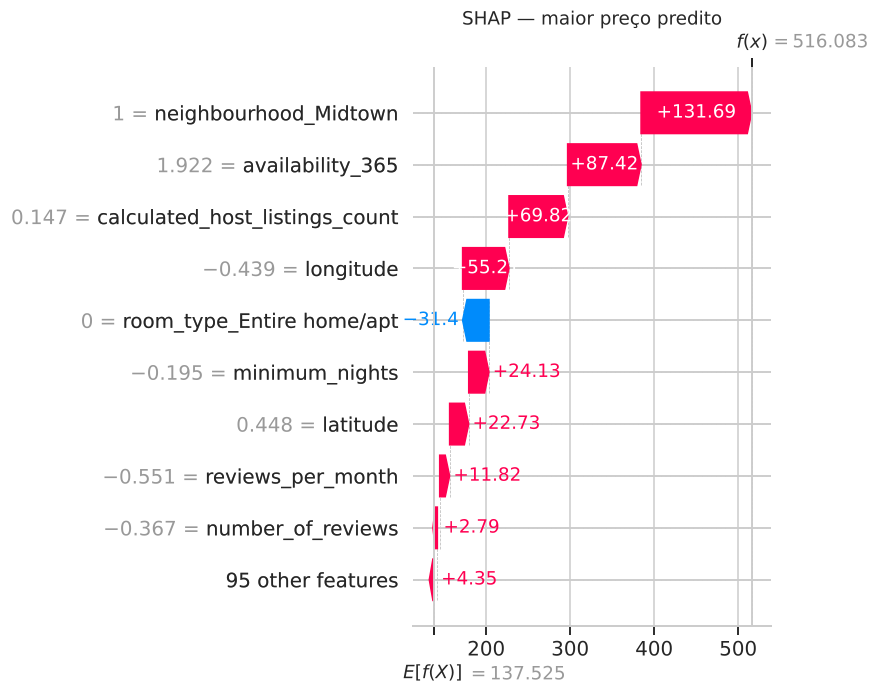

In [ ]:
pred_amostra = pd.Series(melhor.predict(X_shap), index=X_shap.index)
ordem = pred_amostra.sort_values()
escolhidos = {"menor preço predito": ordem.index[0],
              "preço predito mediano": ordem.index[len(ordem) // 2],
            "maior preço predito": ordem.index[-1]}

colunas_ver = ["neighbourhood_group", "neighbourhood", "room_type", "minimum_nights",
            "number_of_reviews", "availability_365", "calculated_host_listings_count"]
for rotulo, idx in escolhidos.items():
    i = X_shap.index.get_loc(idx)
    print(f"{rotulo.upper()} | real: US$ {y_test[idx]:.0f} | predito: US$ {pred_amostra[idx]:.0f}")
    display(X_shap.loc[[idx], colunas_ver])
    contrib = pd.Series(sv.values[i], index=Xt.columns)
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
    print(f"Valor base: {np.ravel(sv.base_values)[i]:.1f}" + (" (escala log)" if escala_log else " US$"))
    print("Top-5 contribuições SHAP:")
    for f, v in top.items():
        if escala_log:
            print(f"  {f:<35} {v:+.3f}  (x{np.exp(v):.2f})")
        else:
            print(f"  {f:<35} {v:+8.1f} US$")
    shap.plots.waterfall(sv[i], max_display=10, show=False)
    plt.title(f"SHAP — {rotulo}"); plt.tight_layout(); plt.show()

Todas partem do mesmo valor base (US$ 137,5, a previsão média):

1. **Menor preço predito — quarto compartilhado em Williamsburg (real US$ 35, predito US$ 26).** Quase toda a queda vem
   de não ser um imóvel inteiro (−US$ 69) e de exigir 30 noites mínimas*(−US$ 24), típico de aluguel mensal. A
   localização (longitude, −US$ 12) também reduz. A alta disponibilidade é o único fator relevante a favor (+US$ 9).
2. **Preço mediano — apartamento inteiro no Harlem (real US$ 100, predito US$ 123).** Ser imóvel inteiro soma
   +US$ 41, mas a localização (Harlem fica ao norte e a leste do centro de Manhattan: longitude −US$ 22 e latitude
   −US$ 11) e a disponibilidade zero (−US$ 24) compensam boa parte. O erro de US$ 23 é pequeno e aceitável.
3. **Maior preço predito — quarto privado em Midtown (real US$ 499, predito US$ 516).** É um caso atípico: mesmo sendo
   quarto privado (−US$ 31 por não ser imóvel inteiro), o modelo prevê mais de US$ 500 por causa de Midtown
   (+US$ 132), disponibilidade o ano todo (+US$ 87) e um anfitrião com 12 anúncios (+US$ 70). Essa combinação
   sugere um quarto de hotel ou *aparthotel* anunciado no Airbnb — o modelo aprendeu esse padrão e acertou bem o preço.

O caso 3 mostra o valor do SHAP: a mesma feature (`room_type`) que domina globalmente pode ser superada, num anúncio
específico, por uma combinação de outras features - o que não aparece numa importância global.

## 4. Discussão

### Limitações do melhor modelo

1. **Não informa a incerteza da previsão.** O modelo devolve um único valor, mas vimos que o erro varia muito com o
   preço: em um anúncio barato ele costuma errar ~US$ 20, em um caro pode errar mais de US$ 200. Para uso real, um
   preço sugerido sem intervalo engana o usuário. Uma alternativa seria regressão quantílica
   (`HistGradientBoostingRegressor(loss="quantile")`) ou *conformal prediction* para gerar intervalos.
2. **A validação aleatória pode ser otimista do ponto de vista espacial.** Com o split aleatório, anúncios do mesmo
   prédio ou quarteirão (inclusive do mesmo anfitrião com vários anúncios quase iguais) caem em treino e em teste ao
   mesmo tempo. O modelo "aprende" preços de vizinhos quase idênticos, e o RMSE medido pode ser melhor do que seria
   para um anúncio realmente novo ou de uma região pouco representada. Uma validação agrupada por anfitrião
   (`GroupKFold` com `host_id`) ou por região daria uma estimativa mais honesta.

### Limitações dos dados

1. **Faltam as variáveis que mais definem o preço.** O dataset não tem tamanho do imóvel, número de quartos/banheiros,
   capacidade de hóspedes, comodidades, fotos nem nota média das reviews. O modelo tenta inferir tudo isso a partir de
   localização e tipo de quarto, o que explica o R² de ~0,5 e o "teto" visto na curva de aprendizado. Além disso,
   `price` é o preço-base anunciado, sem taxas de limpeza, descontos e variação por data ou temporada.
2. **É um retrato de 2019, de um mercado que mudou.** Os dados são anteriores à pandemia e às mudanças regulatórias de
   NYC sobre aluguel de curta duração, que reduziram fortemente a oferta de estadias com menos de 30 noites. A relação
   entre localização, tipo de quarto, estadia mínima e preço provavelmente não é a mesma hoje. Há ainda variáveis
   ambíguas: `availability_365 = 0` pode significar "sempre ocupado" ou "anúncio inativo/bloqueado".

### Ações para operacionalização e manutenção

1. **Empacotar o pipeline completo e validar as entradas.** Serializar o pipeline inteiro (pré-processamento + modelo,
   ex.: `joblib.dump(melhor, "modelo.joblib")`) junto com as versões das bibliotecas, e expor via uma API simples.
   Antes de prever, validar o esquema: tipos, faixas plausíveis (coordenadas dentro de NYC, `minimum_nights` > 0) e
   categorias novas — o `OneHotEncoder(handle_unknown="infrequent_if_exist")` já evita que um bairro novo quebre o
   modelo, mas esses casos devem ser registrados.
2. **Monitorar *drift* e retreinar periodicamente.** Acompanhar a distribuição das entradas (ex.: proporção por
   `room_type` e distrito, mediana de `minimum_nights`) e, quando houver preços reais, o RMSE/MAE em produção por faixa
   de preço. Definir um gatilho (ex.: RMSE 15% acima do de validação ou mudança forte nas distribuições) e uma rotina
   de retreino com dados recentes, comparando o novo modelo com o atual (*champion–challenger*) antes de substituí-lo.